# Plot the steady state spectrum dependence between energy and energy independent losses

In [1]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

import steady state spectrum properties

In [2]:
b_field = 5e-6
density = 1e-24

In [3]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"


with h5py.File(f"{data_dir}/steady_state_spectrum.h5", "r") as f:
    alpha_inj_grid = f["alpha_inj_grid"][()]
    alpha_inj_e_grid = f["alpha_inj_e_grid"][()]
    log10_B_grid = f["log10_B_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]

    mom_grid = f["electron/mom_grid"][()]
    steady_state_grid_full = f["electron/steady_state_grid"][()]

    synch_freq_grid = f["syn_freq_grid"][()] * u.GHz  # only need half the frequencies
    log10_eneratio_grid = f["electron/log10_eneratio_grid"][()]
    log10_ensynchratio_grid = f["electron/log10_ensynchratio_grid"][()]

with h5py.File(f"{data_dir}/steady_state_spectrum_enindep.h5", "r") as f:
    alpha_inj_grid = f["alpha_inj_grid"][()]
    alpha_inj_e_grid = f["alpha_inj_e_grid"][()]
    log10_B_grid = f["log10_B_grid"][()]
    log10_dens_grid = f["log10_dens_grid"][()]

    mom_grid = f["electron/mom_grid"][()]
    steady_state_grid_full_enindep = f["electron/steady_state_grid"][()]

    synch_freq_grid = f["syn_freq_grid"][()] * u.GHz  # only need half the frequencies
    log10_eneratio_grid_enindep = f["electron/log10_eneratio_grid"][()]
    log10_ensynchratio_grid_enindep = f["electron/log10_ensynchratio_grid"][()]

bfield_idx = np.digitize(b_field, 10**log10_B_grid, right=True)
dens_idx = np.digitize(np.log10(density), log10_dens_grid, right=True)

In [4]:
alpha_inj_p_cmap = plt.get_cmap("plasma")
alpha_inj_p_norm = plt.Normalize(vmin=4, vmax=5, clip=True)

spect_type_handles = [
    mlines.Line2D([0], [0], color="k", lw=2.0, alpha=0.8, label="Momentum-dep. losses"),
    mlines.Line2D([0], [0], color="k", lw=2.0, ls="--", alpha=0.8, label="Momentum-indep. losses"),
]

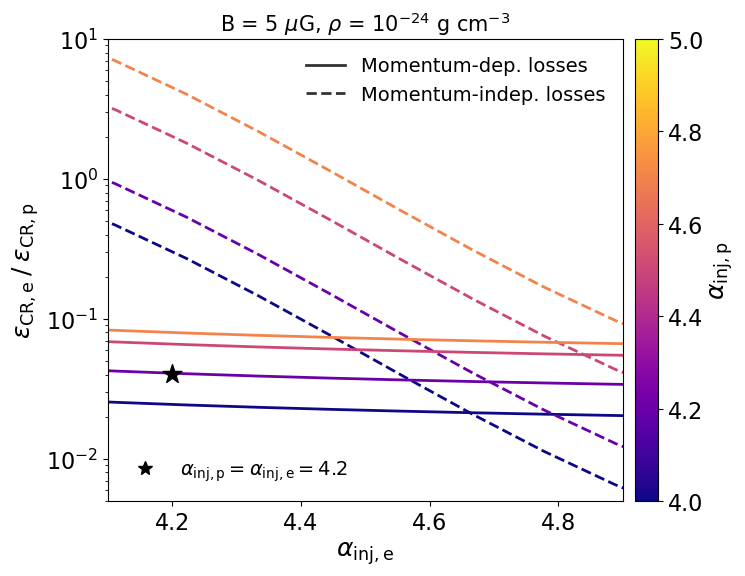

In [5]:
fig, ax = plt.subplots(figsize=(8,6))
for ia, alpha_inj in enumerate([4, 4.2, 4.5, 4.7]):
    alpha_inj_idx  = np.digitize(alpha_inj, alpha_inj_grid, right=True)

    ax.semilogy(alpha_inj_e_grid, 1 / 10**log10_eneratio_grid[alpha_inj_idx, dens_idx, :, bfield_idx], color=alpha_inj_p_cmap(alpha_inj_p_norm(alpha_inj)), lw=2.0)
    ax.semilogy(alpha_inj_e_grid, 1 / 10**log10_eneratio_grid_enindep[alpha_inj_idx, dens_idx, :, bfield_idx], color=alpha_inj_p_cmap(alpha_inj_p_norm(alpha_inj)), ls="--", lw=2.0)

ax.set_xlabel(r"$\alpha_\mathrm{inj,e}$", fontsize=18)
ax.set_ylabel(r"$\epsilon_\mathrm{CR,e} \: / \: \epsilon_\mathrm{CR,p}$", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.scatter(4.2, 1 / 10**log10_eneratio_grid[np.digitize(4.2, alpha_inj_grid, right=True), dens_idx, np.digitize(4.2, alpha_inj_grid, right=True), bfield_idx], s=200, color="k", edgecolor="k", zorder=10, marker="*")

leg1 = ax.legend(handles=spect_type_handles, loc="upper right", fontsize=14, framealpha=0.0, frameon=False)
fig.add_artist(leg1)
ax.legend(handles=[
    mlines.Line2D([0], [0], color="k", marker="*",ms=10, ls="", label=r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj,e} = 4.2$"),
    
], loc="lower left", fontsize=14, framealpha=0.0, frameon=False, ncol=1)
sm = plt.cm.ScalarMappable(cmap=alpha_inj_p_cmap, norm=alpha_inj_p_norm)
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r"$\alpha_\mathrm{inj,p}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)

ax.set_xlim(4.1, 4.9)
ax.set_ylim(5e-3, 1e1)

ax.set_title(fr"B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=15)

fig.savefig(f"{fig_dir}/epratio_withlosses.pdf", bbox_inches="tight", dpi=300)

In [6]:
import matplotlib.colors as mcolors

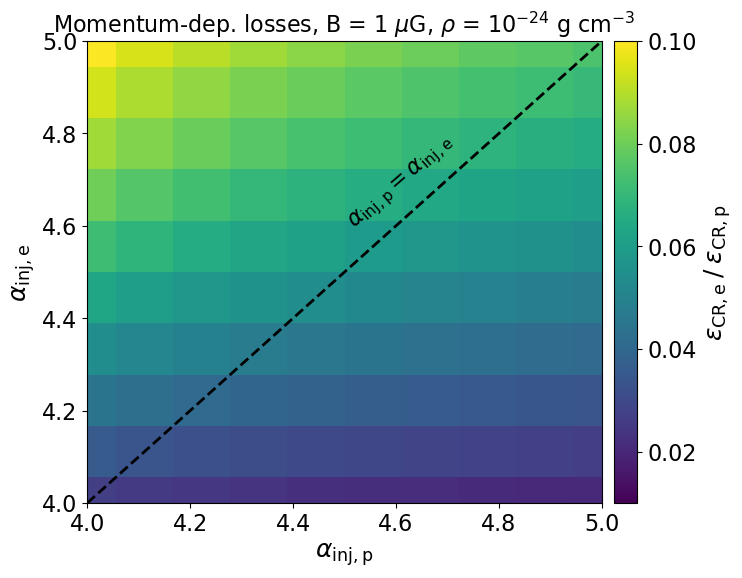

In [14]:
fig, ax = plt.subplots(figsize=(8,6))
AINJ_E, AINJ_P = np.meshgrid(alpha_inj_e_grid, alpha_inj_grid, indexing="ij")
pc = ax.pcolormesh(AINJ_P, AINJ_E, 1 / 10**log10_eneratio_grid[:, dens_idx, :, bfield_idx], cmap="viridis", norm=mcolors.Normalize(vmin=1e-2, vmax=1e-1, clip=True), shading="auto")

ax.set_xlabel(r"$\alpha_\mathrm{inj,p}$", fontsize=18)
ax.set_ylabel(r"$\alpha_\mathrm{inj,e}$", fontsize=18)
cbar = fig.colorbar(pc, ax=ax, pad=0.02)
cbar.set_label(r"$\epsilon_\mathrm{CR,e} \: / \: \epsilon_\mathrm{CR,p}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)
cbar.ax.set_ylim(1e-2, 1e-1)
ax.plot(alpha_inj_grid, alpha_inj_grid, color="k", ls="--", lw=2.0, label=r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj,e}$")

# ax.set_xlabel(r"$\nu$ / Hz", fontsize=18)
# ax.set_ylabel(r"$n_\mathrm{CR,e,synch} \: / \: \epsilon_\mathrm{CR,p}$ [GeV$^{-1}$]", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.annotate(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj,e}$", xy=(4.4, 4.4), xytext=(4.5, 4.6), fontsize=16, color="k", rotation=41)
# sm = plt.cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
# cbar = fig.colorbar(sm, ax=ax, pad=0.02)
# cbar.set_label(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj, e}$", fontsize=18)
# cbar.ax.tick_params(labelsize=16)

ax.set_xlim(4,5)
ax.set_ylim(4,5)
# ax.set_ylim(1e-4, 5e-3)
ax.set_title(fr"Momentum-dep. losses, B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=16)

fig.savefig(f"{fig_dir}/epratio_2d.pdf", bbox_inches="tight", dpi=300)

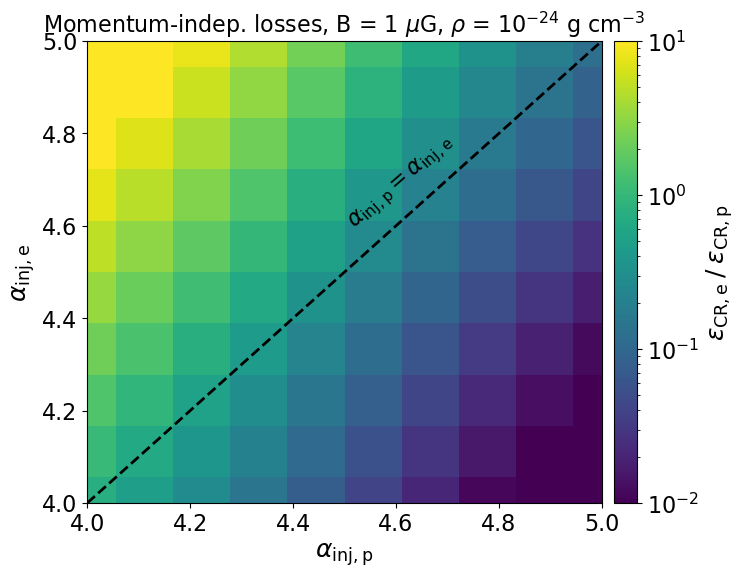

In [15]:
fig, ax = plt.subplots(figsize=(8,6))
AINJ_E, AINJ_P = np.meshgrid(alpha_inj_e_grid, alpha_inj_grid, indexing="ij")
pc = ax.pcolormesh(AINJ_P, AINJ_E, 1 / 10**log10_eneratio_grid_enindep[:, dens_idx, :, bfield_idx], cmap="viridis", norm=mcolors.LogNorm(vmin=1e-2, vmax=1e1, clip=True), shading="auto")

ax.set_xlabel(r"$\alpha_\mathrm{inj,p}$", fontsize=18)
ax.set_ylabel(r"$\alpha_\mathrm{inj,e}$", fontsize=18)
cbar = fig.colorbar(pc, ax=ax, pad=0.02)
cbar.set_label(r"$\epsilon_\mathrm{CR,e} \: / \: \epsilon_\mathrm{CR,p}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)
# cbar.ax.set_ylim(1e-2, 1e-1)
ax.plot(alpha_inj_grid, alpha_inj_grid, color="k", ls="--", lw=2.0, label=r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj,e}$")

# ax.set_xlabel(r"$\nu$ / Hz", fontsize=18)
# ax.set_ylabel(r"$n_\mathrm{CR,e,synch} \: / \: \epsilon_\mathrm{CR,p}$ [GeV$^{-1}$]", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.annotate(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj,e}$", xy=(4.4, 4.4), xytext=(4.5, 4.6), fontsize=16, color="k", rotation=41)
# sm = plt.cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
# cbar = fig.colorbar(sm, ax=ax, pad=0.02)
# cbar.set_label(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj, e}$", fontsize=18)
# cbar.ax.tick_params(labelsize=16)

ax.set_xlim(4,5)
ax.set_ylim(4,5)
# ax.set_ylim(1e-4, 5e-3)

ax.set_title(fr"Momentum-indep. losses, B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=16)

fig.savefig(f"{fig_dir}/epratio_2d_withlosses.pdf", bbox_inches="tight", dpi=300)

In [9]:
alpha_inj_cmap = plt.get_cmap("inferno")
alpha_inj_norm = plt.Normalize(vmin=4, vmax=5, clip=True)

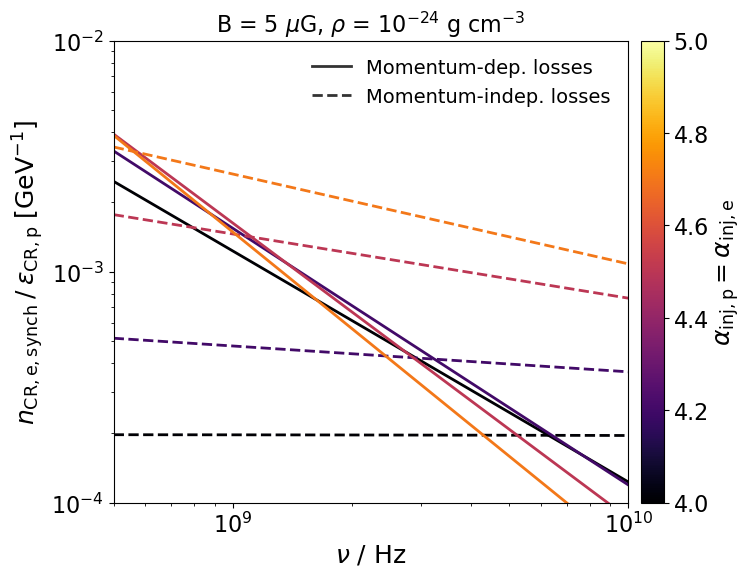

In [10]:
fig, ax = plt.subplots(figsize=(8,6))
for ia, alpha_inj in enumerate([4, 4.2, 4.5, 4.7]):
        alpha_inj_idx  = np.digitize(alpha_inj, alpha_inj_grid, right=True)

        ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), lw=2.0, ls="-")

        ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid_enindep[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), lw=2.0, ls="--")

ax.set_xlabel(r"$\nu$ / Hz", fontsize=18)
ax.set_ylabel(r"$n_\mathrm{CR,e,synch} \: / \: \epsilon_\mathrm{CR,p}$ [GeV$^{-1}$]", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.legend(handles=spect_type_handles, loc="upper right", fontsize=14, framealpha=0.0, frameon=False)
sm = plt.cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj, e}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)

ax.set_xlim(5e8, 1e10)
ax.set_ylim(1e-4, 1e-2)

ax.set_title(fr"B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=16)

fig.savefig(f"{fig_dir}/nsynch_ep_ratio_withlosses.pdf", bbox_inches="tight", dpi=300)

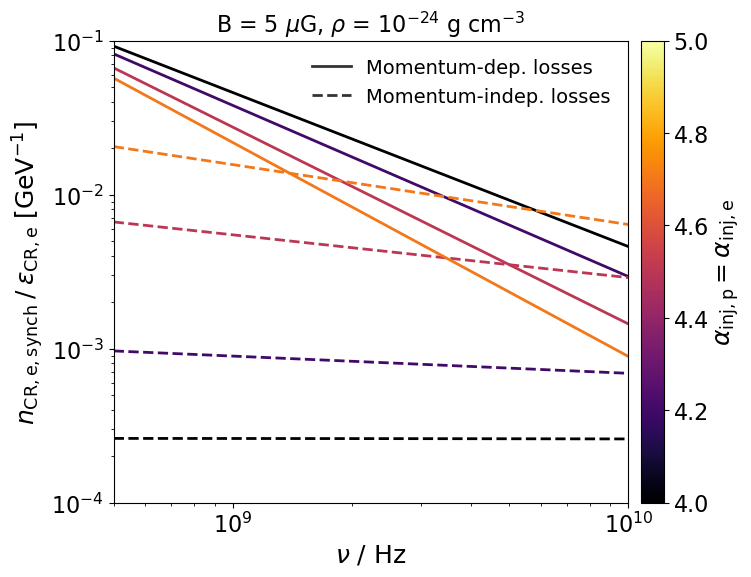

In [11]:
fig, ax = plt.subplots(figsize=(8,6))
for ia, alpha_inj in enumerate([4, 4.2, 4.5, 4.7]):
    alpha_inj_idx  = np.digitize(alpha_inj, alpha_inj_grid, right=True)

    ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :] * 10**log10_eneratio_grid[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), lw=2.0)
    ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid_enindep[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :] * 10**log10_eneratio_grid_enindep[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), ls="--", lw=2.0)

ax.set_xlabel(r"$\nu$ / Hz", fontsize=18)
ax.set_ylabel(r"$n_\mathrm{CR,e,synch} \: / \: \epsilon_\mathrm{CR,e}$ [GeV$^{-1}$]", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)

ax.legend(handles=spect_type_handles, loc="upper right", fontsize=14, framealpha=0.0, frameon=False)
sm = plt.cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj, e}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)

ax.set_xlim(5e8, 1e10)
ax.set_ylim(1e-4, 1e-1)

ax.set_title(fr"B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=16)

fig.savefig(f"{fig_dir}/nsynch_ene_ratio_withlosses.pdf", bbox_inches="tight", dpi=300)

In [12]:
alpha_inj_cmap = plt.get_cmap("plasma")
alpha_inj_norm = plt.Normalize(vmin=4, vmax=5, clip=True)

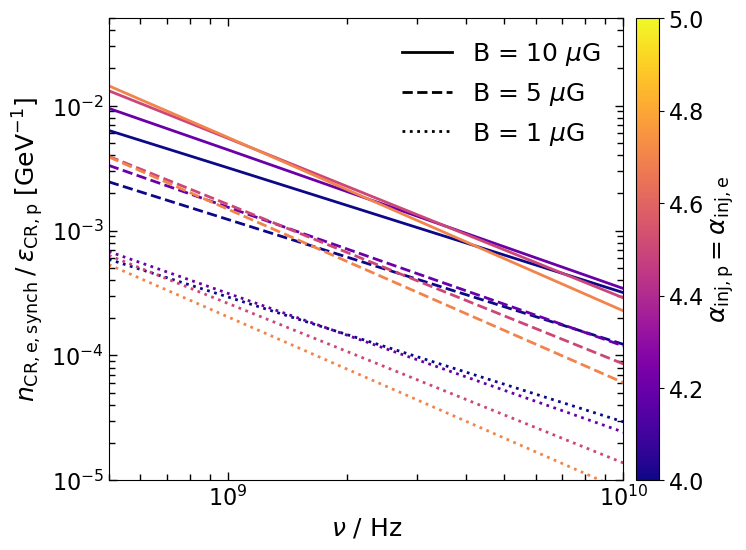

In [13]:
bfield_dens_combos = [
    (1e-5, 1e-24),
    (5e-6, 1e-24),
    (1e-6, 1e-24),
    # (5e-6, 1e-23),
]
combo_lss = ["-", "--", ":", "-."]

import matplotlib.lines as mlines

# Generate handles for the bfield_dens_combos
bfield_handles = [
    mlines.Line2D([], [], color='k', ls=combo_lss[i], label=rf'B = {bfield * 1e6:.0f} $\mu$G', lw=2.0)
    for i, (bfield, dens) in enumerate(bfield_dens_combos)
]

# Example of how to use these handles in a legend
# ax.legend(handles=bfield_handles, title='B-field and Density Combinations')

fig, ax = plt.subplots(figsize=(8,6))
for ic, (b_field, density) in enumerate(bfield_dens_combos):
    bfield_idx = np.digitize(b_field, 10**log10_B_grid, right=True)
    dens_idx = np.digitize(np.log10(density), log10_dens_grid, right=True)
    for ia, alpha_inj in enumerate([4, 4.2, 4.5, 4.7]):
        alpha_inj_idx  = np.digitize(alpha_inj, alpha_inj_grid, right=True)

        ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), lw=2.0, ls=combo_lss[ic])
        # ax.loglog(synch_freq_grid*1e9, 1 / 10**log10_ensynchratio_grid_enindep[alpha_inj_idx, dens_idx, alpha_inj_idx, bfield_idx, :], color=alpha_inj_cmap(alpha_inj_norm(alpha_inj)), ls="--", lw=2.0)

ax.set_xlabel(r"$\nu$ / Hz", fontsize=18)
ax.set_ylabel(r"$n_\mathrm{CR,e,synch} \: / \: \epsilon_\mathrm{CR,p}$ [GeV$^{-1}$]", fontsize=18)

ax.tick_params(axis='both', which='major', labelsize=16, right=True, top=True, direction='in', size=6, width=1.0)
ax.tick_params(axis='both', which='minor', labelsize=16, right=True, top=True, direction='in', size=4, width=1.0)

ax.legend(handles=bfield_handles, loc="upper right", fontsize=18, framealpha=0.0, frameon=False)
sm = plt.cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r"$\alpha_\mathrm{inj,p} = \alpha_\mathrm{inj, e}$", fontsize=18)
cbar.ax.tick_params(labelsize=16)

ax.set_xlim(5e8, 1e10)
ax.set_ylim(1e-5, 5e-2)

# ax.set_title(fr"B = {b_field*1e6:.0f} $\mu$G, $\rho$ = 10$^{{{np.log10(density):.0f}}}$ g cm$^{{-3}}$", fontsize=16)
fig.savefig(f"{fig_dir}/nelesynch_ep_ratio.pdf", bbox_inches="tight", dpi=300)